# PODs across readouts

In [2]:
import polars as pl
import pandas as pd
from scipy.stats import ttest_rel, pearsonr
import numpy as np


output_dir = "../outputs"
input_dir = "/Users/ollitrault/Documents/projects/2025_Ollitrault_BSC/modules/02_processing/outputs"

In [5]:
# Get info to convert PODs
conc_conv = pl.read_parquet(f"{input_dir}/level4b_axiom.parquet")
conc_conv = conc_conv.filter(pl.col("Metadata_compound") != "DMSO").select(
    ["Metadata_compound", "Metadata_concentration"]
).group_by("Metadata_compound").agg([
    pl.col("Metadata_concentration").min().alias("Metadata_Min_Conc")
])

conc_conv = conc_conv.with_columns(
    (pl.col("Metadata_Min_Conc")/3).log10().abs().alias("Metadata_Conc_Shift")
)

def conv_POD_um(pod_df, conv_df, pod_col, conv_pod_nm):
    pod_df = pod_df.join(conv_df, on="Metadata_compound")

    pod_df = pod_df.with_columns(
        (10 ** (pl.col(pod_col) - pl.col("Metadata_Conc_Shift"))).alias(conv_pod_nm)
    ).drop(["Metadata_Min_Conc", "Metadata_Conc_Shift"])

    return pod_df

## Compare PODs across just global MD

In [25]:
data = pl.read_parquet(f"{input_dir}/level4b_axiom.parquet")

dino = pl.read_parquet(f"{output_dir}/pods/pods_axiom_cp.parquet").filter(
    (pl.col("gene.id") == "gmd") &
    (pl.col("all.pass") == True) &
    (pl.col("SDres") < 3*pl.col("SDctrl"))
).select(["Metadata_compound", "bmd"]).rename({"bmd": "Metadata_dino_POD"})
dino = conv_POD_um(dino, conc_conv, "Metadata_dino_POD", "Metadata_dino_POD_um")
dino.shape

(545, 3)

In [26]:
data = data.join(dino, on="Metadata_compound", how="left")

# Log scale
all_pods = data.select([
    "Metadata_compound",
    "Metadata_dino_POD",
]).unique()

all_pods_long = all_pods.unpivot(
    index=["Metadata_compound"],
    on=["Metadata_dino_POD"],
    variable_name="POD_Type",
    value_name="POD_Value"
).drop_nulls().to_pandas()

all_pods_long['POD_Type'] = pd.Categorical(
    all_pods_long['POD_Type'],
    categories=["Metadata_dino_POD"],
    ordered=True
)

# um scale
all_pods_um = data.select([
    "Metadata_compound",
    "Metadata_dino_POD_um",
]).unique()

all_pods_um = all_pods_um.unpivot(
    index=["Metadata_compound"],
    on=["Metadata_dino_POD_um"],
    variable_name="POD_Type",
    value_name="POD_Value"
).drop_nulls().to_pandas()

all_pods_um['POD_Type'] = pd.Categorical(
    all_pods_um['POD_Type'],
    categories=["Metadata_dino_POD_um"],
    ordered=True
)

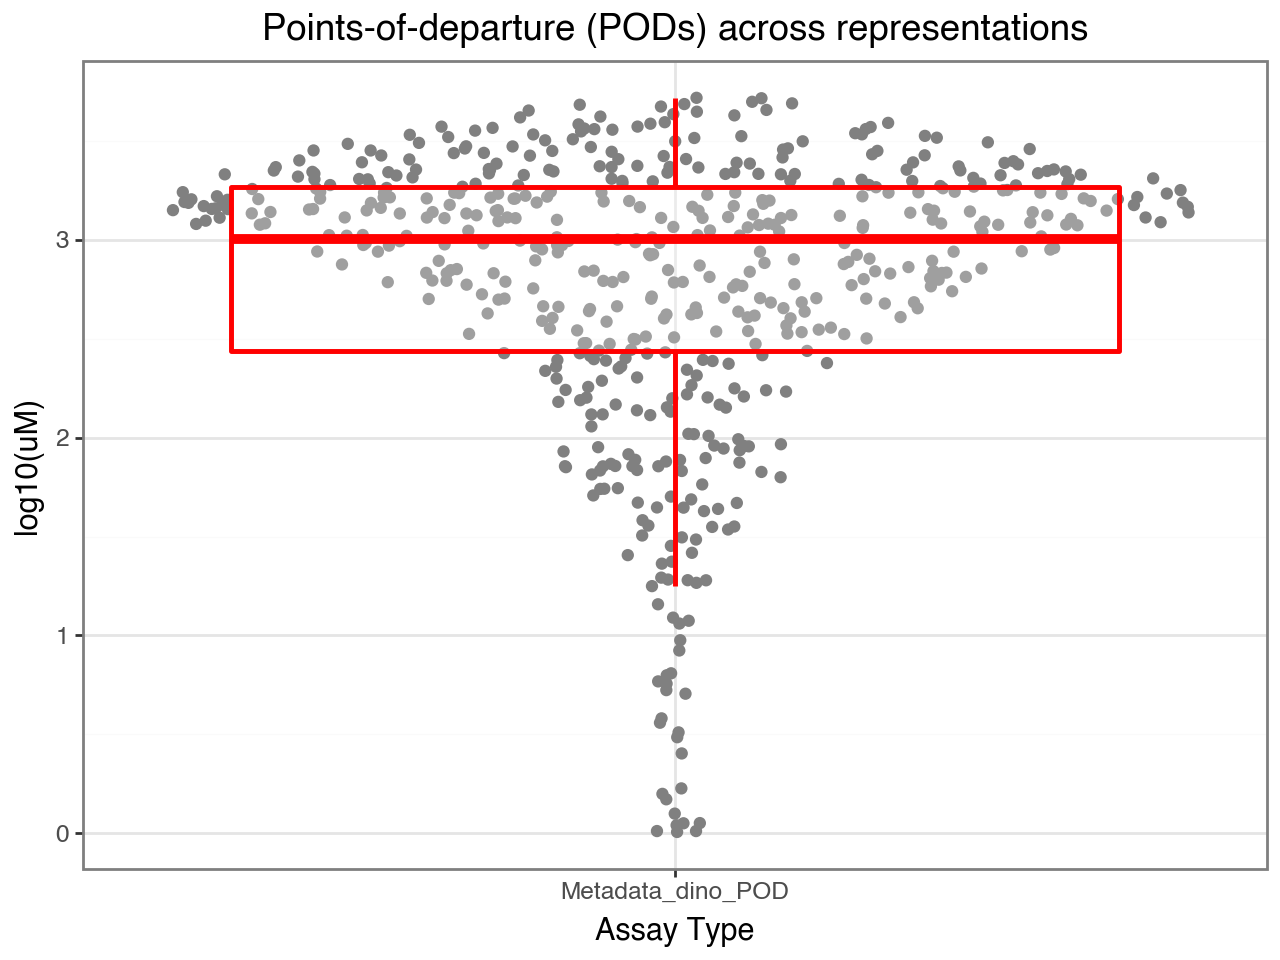

In [27]:
from plotnine import ggplot, aes, theme_bw, geom_boxplot, geom_sina, labs

plot = (
    ggplot(all_pods_long, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(title='Points-of-departure (PODs) across representations', x='Assay Type', y='log10(uM)') 
    + theme_bw()
)
plot.show()

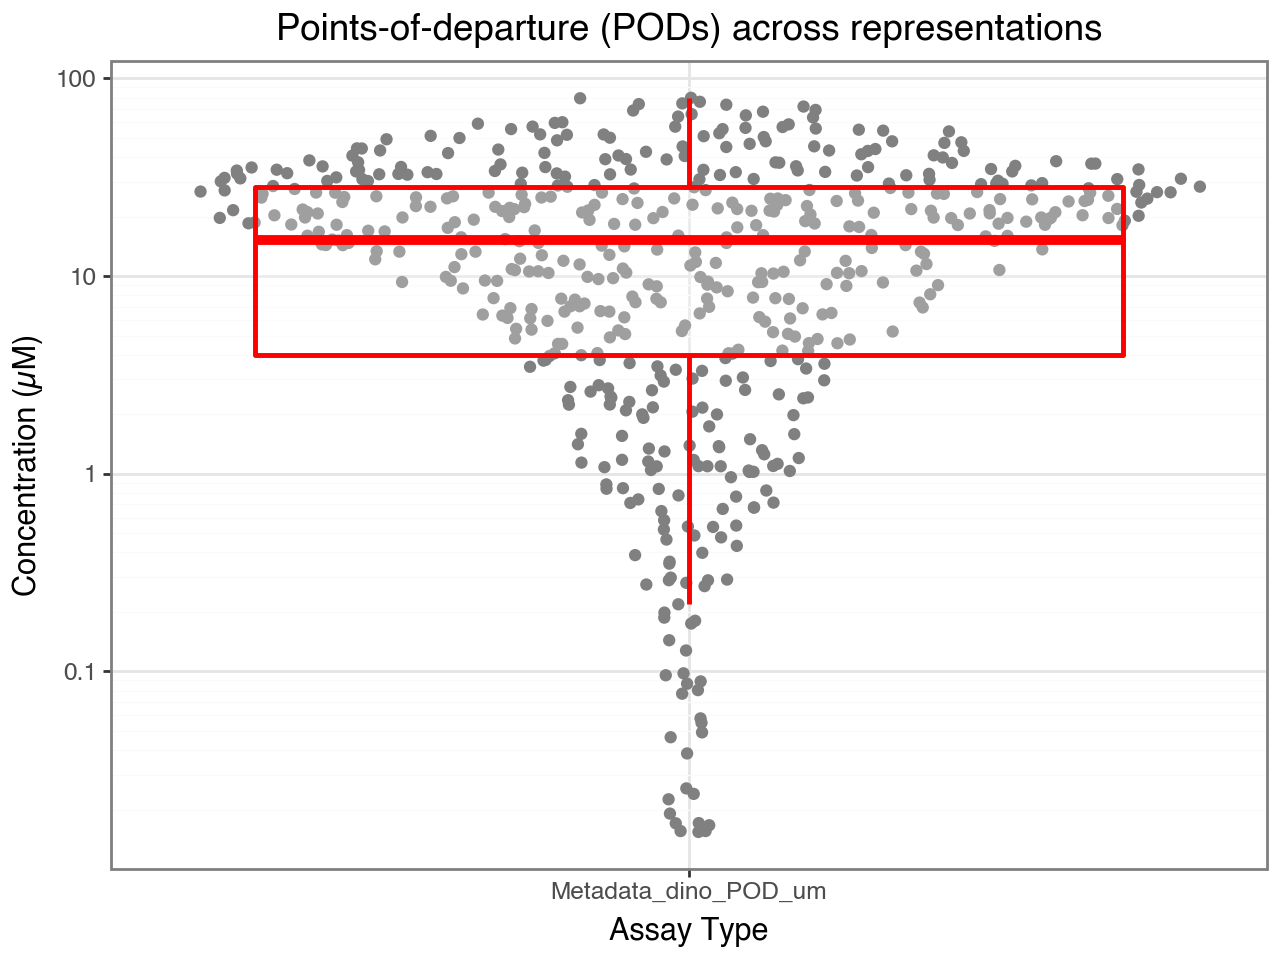

In [28]:
from plotnine import ggplot, aes, theme_bw, geom_boxplot, geom_sina, labs, scale_y_log10

plot = (
    ggplot(all_pods_um, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(title='Points-of-departure (PODs) across representations', x='Assay Type', y='Concentration (µM)') 
    + theme_bw()
    + scale_y_log10()
)
plot.show()

## Compare PODs lowest categorical MD

In [29]:
data = pl.read_parquet(f"{input_dir}/level4b_axiom.parquet")

dino = pl.read_parquet(f"{output_dir}/pods/pods_axiom_cp.parquet").filter(
    (pl.col("gene.id") != "gmd") &
    (pl.col("all.pass") == True) &
    (pl.col("SDres") < 3*pl.col("SDctrl"))
)
dino = conv_POD_um(dino, conc_conv, "bmd", "bmd_um")
dino = dino.group_by("Metadata_compound").agg(
    pl.col("bmd").min().alias("bmd"),
    pl.col("bmd_um").min().alias("bmd_um")
).select(["Metadata_compound", "bmd", "bmd_um"]).rename({
    "bmd": "Metadata_dino_cmd_POD",
    "bmd_um": "Metadata_dino_cmd_POD_um"})
print(dino.shape)
data = data.join(dino, on="Metadata_compound", how="left")

all_cmd_pods = data.select([
    "Metadata_compound",
    "Metadata_dino_cmd_POD",
    "Metadata_dino_cmd_POD_um",
]).unique()

all_cmd_pods_long = all_cmd_pods.unpivot(
    index=["Metadata_compound"],
    on=["Metadata_dino_cmd_POD",
        "Metadata_dino_cmd_POD_um"],
    variable_name="POD_Type",
    value_name="POD_Value"
).drop_nulls()


all_cmd_pods_um = all_cmd_pods_long.filter(pl.col("POD_Type").is_in(["Metadata_dino_cmd_POD_um"])).to_pandas()
all_cmd_pods_long = all_cmd_pods_long.filter(pl.col("POD_Type").is_in(["Metadata_dino_cmd_POD"])).to_pandas()

all_cmd_pods_long['POD_Type'] = pd.Categorical(
    all_cmd_pods_long['POD_Type'],
    categories=["Metadata_dino_cmd_POD"],
    ordered=True
)

all_cmd_pods_um['POD_Type'] = pd.Categorical(
    all_cmd_pods_um['POD_Type'],
    categories=["Metadata_dino_cmd_POD_um"],
    ordered=True
)

(625, 3)


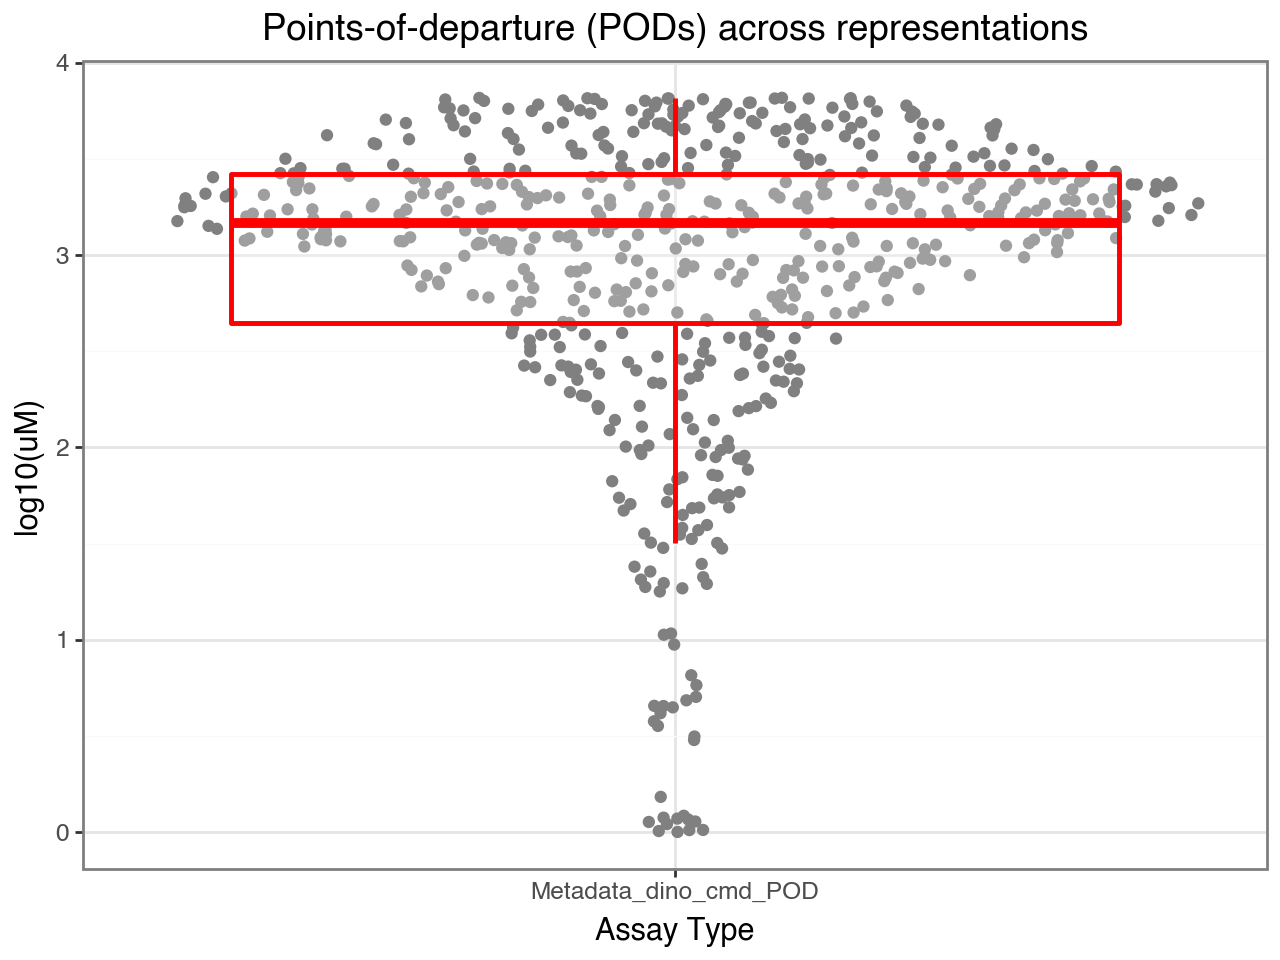

In [19]:
from plotnine import ggplot, aes, theme_bw, geom_boxplot, geom_sina, labs

plot = (
    ggplot(all_cmd_pods_long, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(title='Points-of-departure (PODs) across representations', x='Assay Type', y='log10(uM)') 
    + theme_bw()
)
plot.show()

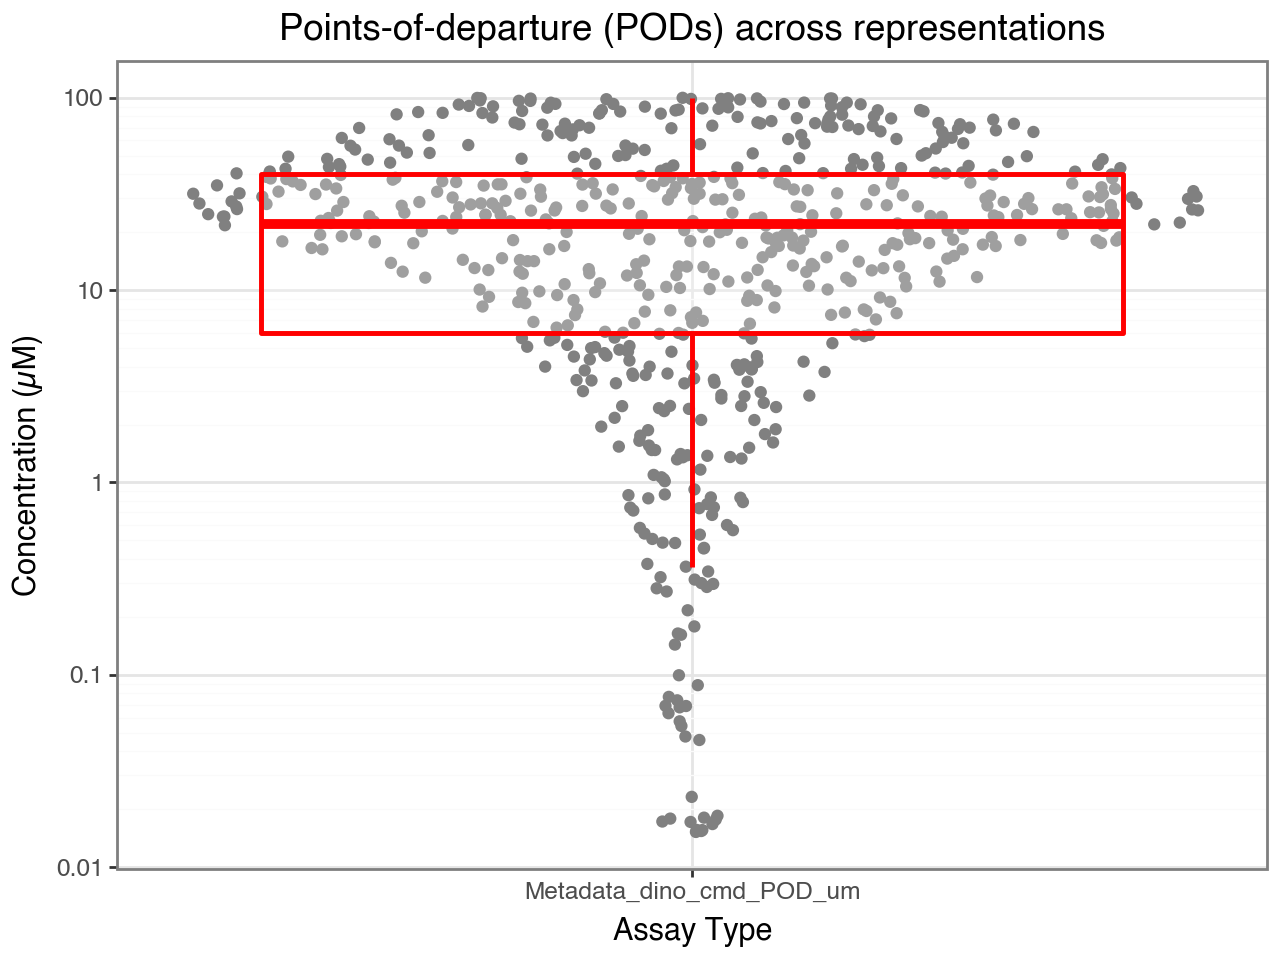

In [20]:
from plotnine import ggplot, aes, theme_bw, geom_boxplot, geom_sina, labs, scale_y_log10

plot = (
    ggplot(all_cmd_pods_um, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(title='Points-of-departure (PODs) across representations', x='Assay Type', y='Concentration (µM)') 
    + theme_bw()
    + scale_y_log10()
)
plot.show()

## Visualize all together

In [21]:
gmd_cmd_pods = pl.concat([
    pl.from_pandas(all_pods_long), pl.from_pandas(all_cmd_pods_long)
], how="vertical").to_pandas()

gmd_cmd_pods['POD_Type'] = pd.Categorical(
    gmd_cmd_pods['POD_Type'],
    categories=["Metadata_dino_POD", "Metadata_dino_cmd_POD"],
    ordered=True
)

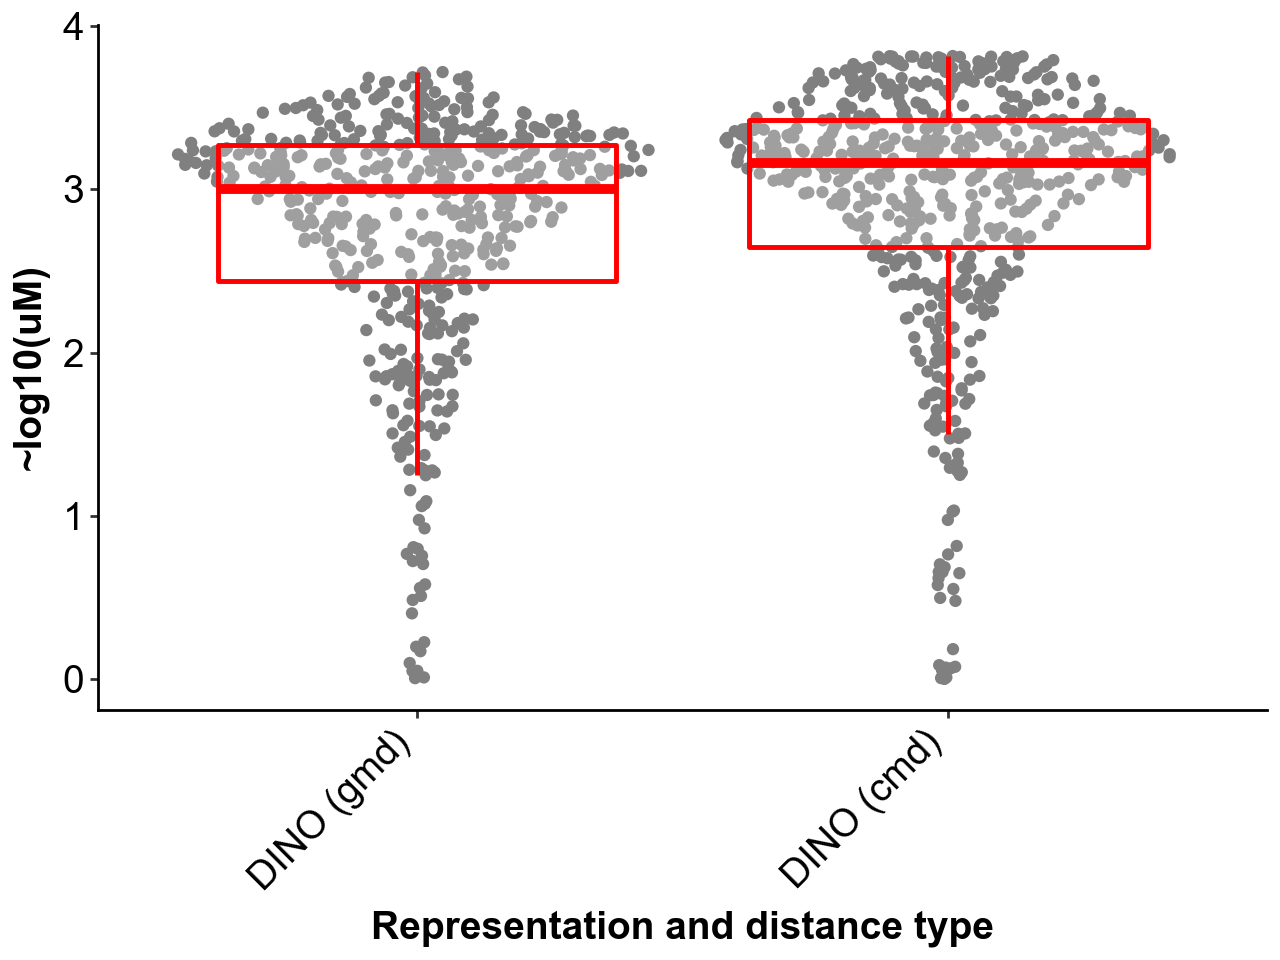

In [22]:
from plotnine import ggplot, aes, theme_classic, geom_boxplot, geom_sina, labs, theme, element_text, scale_x_discrete

plot = (
    ggplot(gmd_cmd_pods, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(x='Representation and distance type', y='~log10(uM)') 
    + theme_classic()
    + theme(
        axis_text_x=element_text(angle=45, hjust=1, color='black', size=14, family='Arial'),
        axis_text_y=element_text(color='black', size=14, family='Arial'),
        axis_title_x=element_text(size=14, color='black', weight='bold', family='Arial'),
        axis_title_y=element_text(size=14, color='black', weight='bold', family='Arial'),
        )
    + scale_x_discrete(labels={
        "Metadata_dino_POD": "DINO (gmd)",
        "Metadata_dino_cmd_POD": "DINO (cmd)",
    })
)
plot.show()

In [23]:
gmd_cmd_pods_um = pl.concat([
    pl.from_pandas(all_pods_um), pl.from_pandas(all_cmd_pods_um)
], how="vertical").pivot(
    index="Metadata_compound",
    on="POD_Type",
    values="POD_Value"
)

print(gmd_cmd_pods_um.shape)
gmd_cmd_pods_um = gmd_cmd_pods_um.drop_nulls()
print(gmd_cmd_pods_um.shape)

gmd_cmd_pods_um = gmd_cmd_pods_um.unpivot(
    index=["Metadata_compound"],
    on=["Metadata_dino_POD_um", "Metadata_dino_cmd_POD_um"],
    variable_name="POD_Type",
    value_name="POD_Value"
).drop_nulls().to_pandas()

gmd_cmd_pods_um['POD_Type'] = pd.Categorical(
    gmd_cmd_pods_um['POD_Type'],
    categories=["Metadata_dino_POD_um", "Metadata_dino_cmd_POD_um"],
    ordered=True
)

(641, 3)
(529, 3)


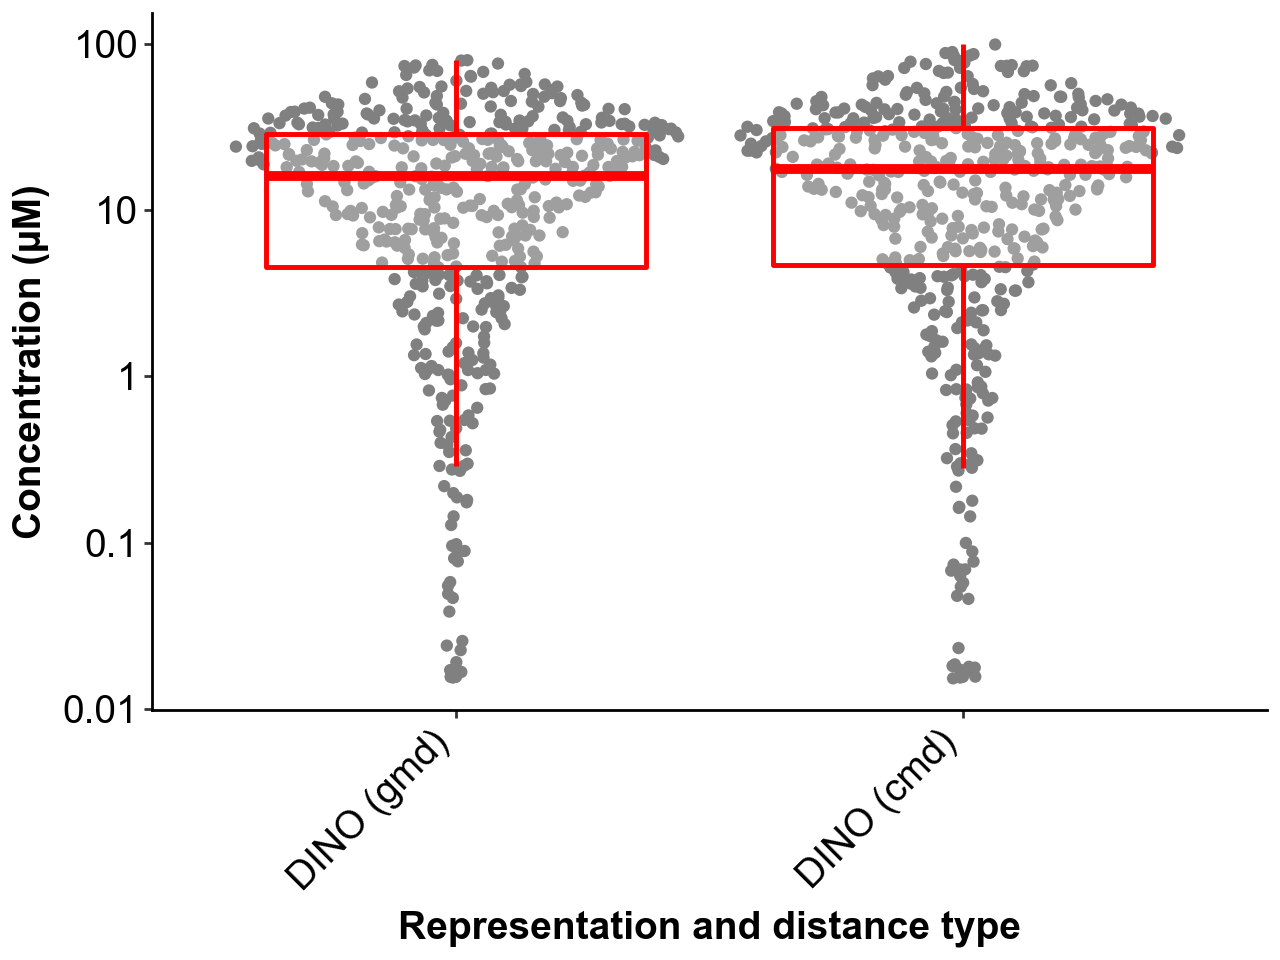

In [24]:
from plotnine import ggplot, aes, theme_classic, geom_boxplot, geom_sina, labs, theme, element_text, scale_x_discrete, scale_y_log10

plot = (
    ggplot(gmd_cmd_pods_um, aes(x='POD_Type', y='POD_Value')) 
    + geom_sina(color="grey") 
    + geom_boxplot(color="red", alpha=0.25, size=1, outlier_alpha=0)
    + labs(x='Representation and distance type', y='Concentration (µM)') 
    + theme_classic()
    + theme(
        axis_text_x=element_text(angle=45, hjust=1, color='black', size=14, family='Arial'),
        axis_text_y=element_text(color='black', size=14, family='Arial'),
        axis_title_x=element_text(size=14, color='black', weight='bold', family='Arial'),
        axis_title_y=element_text(size=14, color='black', weight='bold', family='Arial'),
        )
    + scale_x_discrete(labels={
        "Metadata_dino_POD_um": "DINO (gmd)",
        "Metadata_dino_cmd_POD_um": "DINO (cmd)",
    })
    + scale_y_log10()
)
plot.show()